## K Nearest Neighbour Classifier

### Step 1: Import Libraries

Import the core libraries needed for data manipulation, visualization, and numerical computation.

| Library | Purpose |
|---|---|
| `pandas` | Tabular data manipulation and DataFrames |
| `seaborn` | Statistical data visualization |
| `matplotlib` | Low-level 2D plotting |
| `numpy` | Numerical arrays, linear algebra, and vectorized math |

> [!NOTE]
> `%matplotlib inline` is a Jupyter magic command — it embeds plots directly inside the notebook output instead of opening a separate window.

In [39]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
%matplotlib inline

### Step 2: Generate Synthetic Classification Dataset

`make_classification` generates a random binary classification problem with controlled properties.

| Parameter | Value | Meaning |
|---|---|---|
| `n_samples` | 1000 | Total number of data points |
| `n_features` | 3 | Total number of features |
| `n_redundant` | 1 | Features that are linear combinations of informative features |
| `n_classes` | 2 | Binary target: class 0 and class 1 |
| `random_state` | 999 | Fixed seed for reproducibility |

Each row of $X$ is a feature vector $\mathbf{x} \in \mathbb{R}^3$. Each entry in $y$ is a binary label $y \in \{0, 1\}$:

$$X \in \mathbb{R}^{1000 \times 3}, \quad y \in \{0, 1\}^{1000}$$

In [40]:
from sklearn.datasets import make_classification

X, y = make_classification(
    n_samples=1000, # 1000 observations 
    n_features=3, # 3 total features
     n_redundant=1,
    n_classes=2, # binary target/label 
    random_state=999 
)

#### Visualize Dataset Distribution

Plot all three feature pairs as scatter plots to understand the class separability before training.

**What we look for:**
- Are the two classes visually separable in any feature pair?
- Which feature pair gives the cleanest boundary?
- Are there overlapping regions where KNN may struggle?

Each subplot plots one class (Class 0 in blue, Class 1 in orange) against two features. A clear visual gap between classes in any subplot means KNN should perform well in that 2D subspace.

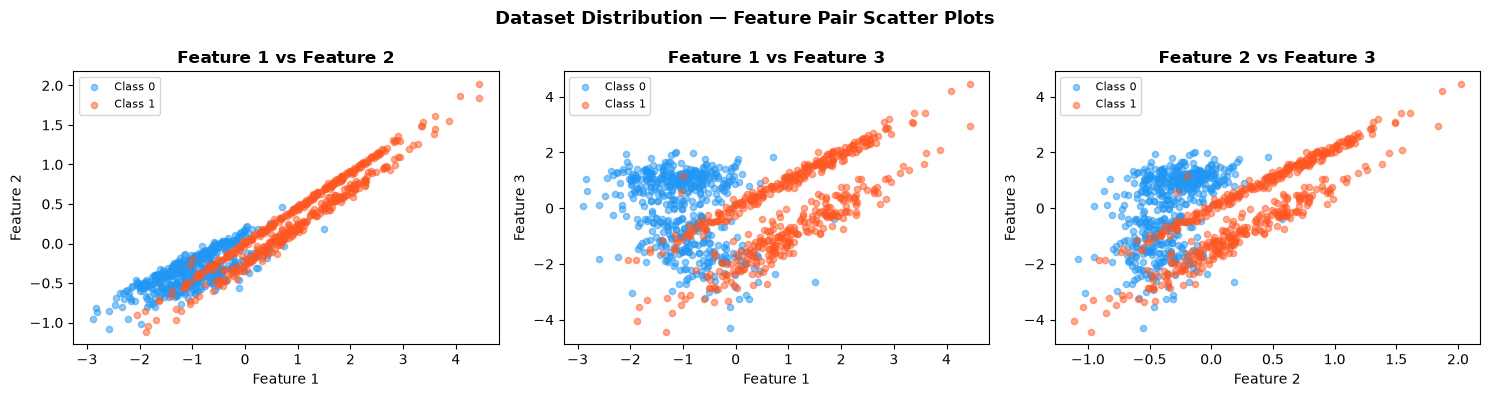

Class 0: 502 samples  |  Class 1: 498 samples


In [41]:
# --- Plot 1: Dataset Distribution (all 3 feature pairs) ---
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
feature_pairs = [(0, 1), (0, 2), (1, 2)]
cls_colors = ['#2196F3', '#FF5722']

for ax, (i, j) in zip(axes, feature_pairs):
    for cls, color in zip([0, 1], cls_colors):
        mask = y == cls
        ax.scatter(X[mask, i], X[mask, j], c=color, alpha=0.5, s=20, label=f'Class {cls}')
    ax.set_xlabel(f'Feature {i+1}')
    ax.set_ylabel(f'Feature {j+1}')
    ax.set_title(f'Feature {i+1} vs Feature {j+1}', fontweight='bold')
    ax.legend(fontsize=8)

plt.suptitle('Dataset Distribution — Feature Pair Scatter Plots', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()
print(f'Class 0: {np.sum(y==0)} samples  |  Class 1: {np.sum(y==1)} samples')

### Step 3: Inspect the Feature Matrix

Display the feature matrix $X$ to verify its shape and value ranges before modelling.

$$X = \begin{pmatrix} x_{11} & x_{12} & x_{13} \\ x_{21} & x_{22} & x_{23} \\ \vdots & \vdots & \vdots \\ x_{n1} & x_{n2} & x_{n3} \end{pmatrix} \in \mathbb{R}^{n \times d}, \quad n = 1000,\ d = 3$$

Each row $\mathbf{x}_i = [x_{i1},\ x_{i2},\ x_{i3}]$ is one sample's feature vector that KNN will use to compute distances.

### Step 4: Split into Training and Test Sets

Divide the dataset into a **training set** (used to fit the model) and a **test set** (used to evaluate generalization on unseen data).

$$n_{\text{train}} = 0.67 \times 1000 = 670\ \text{samples}, \qquad n_{\text{test}} = 0.33 \times 1000 = 330\ \text{samples}$$

| Split | Size | Purpose |
|---|---|---|
| `X_train`, `y_train` | 670 samples | KNN stores these points and labels |
| `X_test`, `y_test` | 330 samples | Held out — evaluated only after training |

> [!WARNING]
> KNN memorizes the entire training set. Evaluating on training data gives an unrealistically optimistic score because the model would simply retrieve its own neighbors. The test set must remain **unseen** until the final evaluation step.

In [42]:
from sklearn.model_selection import train_test_split

In [43]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.33, random_state=42)

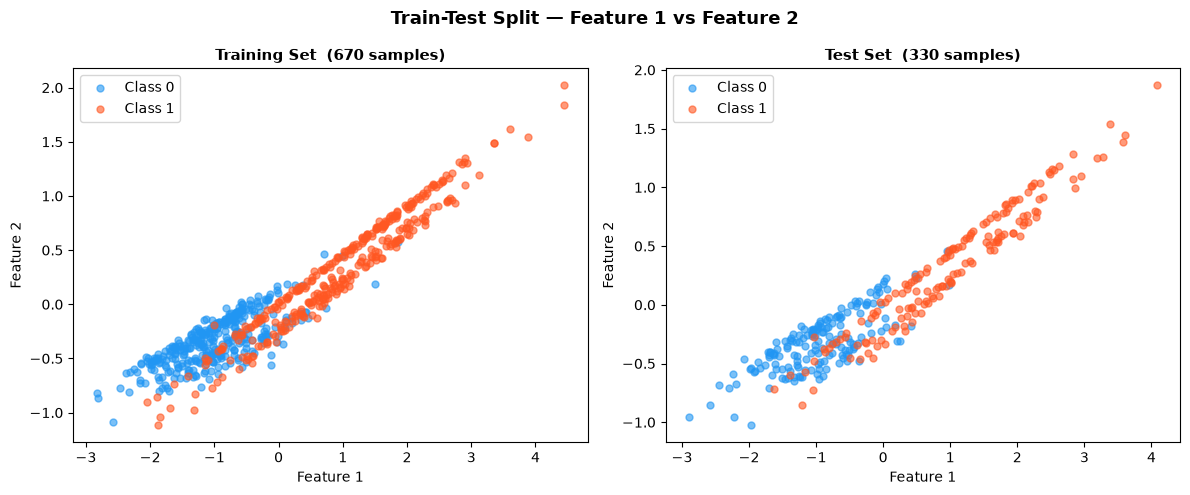

In [44]:
# --- Plot 2: Train / Test Split Visualization ---
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
cls_colors = {0: '#2196F3', 1: '#FF5722'}

for ax, (X_data, y_data, title) in zip(axes, [
    (X_train, y_train, f'Training Set  ({len(y_train)} samples)'),
    (X_test,  y_test,  f'Test Set  ({len(y_test)} samples)')
]):
    for cls in [0, 1]:
        mask = y_data == cls
        ax.scatter(X_data[mask, 0], X_data[mask, 1],
                   c=cls_colors[cls], alpha=0.6, s=25, label=f'Class {cls}')
    ax.set_title(title, fontsize=11, fontweight='bold')
    ax.set_xlabel('Feature 1')
    ax.set_ylabel('Feature 2')
    ax.legend()

plt.suptitle('Train-Test Split — Feature 1 vs Feature 2', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

### Step 5: Instantiate and Train the KNN Classifier

- **KNN training** simply stores the scaled training data — no parameters are learned. All computation is deferred to prediction time (lazy learning).

**KNN Classification — prediction rule for a query $\mathbf{x}$:**

- **Step 1 — Compute Euclidean distance** to every training point:

$$d(\mathbf{x},\ \mathbf{x}_i) = \sqrt{\sum_{j=1}^{d}(x_j - x_{ij})^2}$$

- **Step 2 — Identify the $k$ nearest neighbors:**

$$\mathcal{N}_k(\mathbf{x}) = \{k\ \text{training points with smallest}\ d(\mathbf{x}, \mathbf{x}_i)\}$$

- **Step 3 — Majority vote:**

$$\hat{y}(\mathbf{x}) = \underset{c}{\arg\max}\ \sum_{i \in \mathcal{N}_k(\mathbf{x})} \mathbf{1}(y_i = c)$$

**How this creates the decision boundary:**

The majority vote formula is applied to **thousands of grid points** to create the decision boundary visualization:
- For **one test point**: apply steps 1–3 → get a single class prediction
- For a **mesh grid of points**: apply steps 1–3 to each grid point across the full feature space
- **Color each grid point** by its predicted class (blue for Class 0, orange for Class 1)
- **Where the colors change** = the **decision boundary** *(see Plot 3)*

| Parameter | Value | Meaning |
|---|---|---|
| `n_neighbors` | 5 | Use the 5 nearest neighbors to decide the class |
| `algorithm` | `'auto'` | Scikit-learn picks brute-force, KD-tree, or ball tree automatically |

In [45]:
from sklearn.neighbors import KNeighborsClassifier

In [46]:
classifier=KNeighborsClassifier(n_neighbors=5,algorithm='auto')
classifier.fit(X_train,y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


#### Visualize KNN Decision Boundary

> [!NOTE]
> The true decision boundary for this dataset exists in **3D** — it separates classes across all three features (Feature 1, Feature 2, Feature 3) simultaneously. Because we cannot render a 3D boundary directly, we plot a **2D slice** using only Feature 1 and Feature 2 by training a separate `clf_2d` on those two features alone.

---

**1. What is the step size ($h = 0.05$)?**

The step size determines how **densely** we create points across the feature space when drawing the decision boundary. It is a **visualization parameter** — it does NOT change the KNN model or its predictions.

Suppose Feature 1 ranges from 0 to 5, and Feature 2 ranges from 0 to 5:

| Step size | Grid density | Boundary quality |
|---|---|---|
| $h = 1.0$ | Very few points | Very coarse |
| $h = 0.5$ | More points | Moderate |
| $h = 0.1$ | Fine grid | Good |
| $h = 0.05$ | Very fine grid | Very smooth |
| $h = 0.01$ | Extremely dense | Extremely fine |

<div align="center">
  <img src="images/How Step Size affects Grid Density in KNN Classification.png" width="550" alt="How Step Size affects Grid Density in KNN Classification">
</div>

> [!IMPORTANT]
> **$h$ controls how many locations we test to draw the boundary.**
> **$k$ controls how many neighbours vote on a prediction.**
> They are completely independent parameters.

---

**2. How many grid points are generated?**

Using `np.arange`, which excludes the endpoint:

$$\text{Points per axis} = \frac{5 - 0}{0.05} = 100$$

$$\text{Total grid points} = 100 \times 100 = \boxed{10{,}000 \text{ grid points}}$$

Each of these 10,000 points needs a class prediction from the KNN model.

---

**3. For each grid point, do we calculate distance to all training samples?**

**Yes — for brute-force search.** For every grid point, KNN calculates its Euclidean distance to all 1,000 training samples, then selects the $k=5$ closest.

**Example — one grid point $G_1 = (1.5, 2.0)$:**

1. Compute distance to all 1,000 training points
2. Sort distances, select the 5 smallest
3. Count votes: e.g., 4 Class 0, 1 Class 1 → **Predict Class 0**

Then move to $G_2$, repeat — for all 10,000 grid points.

---

**4. Total number of distance calculations**

$$\text{Distance calculations} = \text{Grid points} \times \text{Training samples} = 10{,}000 \times 1{,}000 = \boxed{10{,}000{,}000}$$

That is **10 million distance calculations** — just for the visualization!

> [!NOTE]
> This describes brute-force search. If `algorithm='auto'` selects a KD-tree or Ball-tree, scikit-learn may avoid comparing every grid point against all 1,000 training samples by pruning branches that cannot contain the nearest neighbors.

---

**5. How the decision boundary is calculated — step by step**

**Step 1: Create a dense mesh grid** covering the 2D feature space with step size $h = 0.05$:
$$\text{Grid points: } (\mathbf{x}^*_1, \mathbf{x}^*_2), (\mathbf{x}^*_3, \mathbf{x}^*_4), \ldots, (\mathbf{x}^*_n, \mathbf{x}^*_{n+1})$$

**Step 2: For each grid point, apply the majority vote formula:**

For every grid point $\mathbf{x}^*$, repeat:
1. Compute Euclidean distance to all training points:
   $$d_i = \sqrt{(x^*_1 - x_{i1})^2 + (x^*_2 - x_{i2})^2}$$
2. Find the $k=5$ nearest neighbors with smallest distances
3. Count neighbors by class: How many are Class 0? How many are Class 1?
4. Predict the class with the higher count:
   $$\hat{y}(\mathbf{x}^*) = \underset{c}{\arg\max} \sum_{i \in \mathcal{N}_k(\mathbf{x}^*)} \mathbf{1}(y_i = c)$$

**Example — Majority vote applied to three grid points:**

| Grid Point | Neighbors Count | Prediction |
|---|---|---|
| $(0.1, 0.2)$ | 4 Class 0, 1 Class 1 | **Class 0** (blue) |
| $(1.5, 2.0)$ | 1 Class 0, 4 Class 1 | **Class 1** (orange) |
| $(0.0, 0.0)$ | 3 Class 0, 2 Class 1 | **Class 0** (blue) |

**Step 3: Color each grid point** based on its predicted class:
- Prediction = **Class 0** → Color **blue**
- Prediction = **Class 1** → Color **orange**

**Step 4: Find the boundary** — Where the color changes:
- The color transition from blue to orange = the **decision boundary line**
- `plt.contour()` automatically draws this boundary by finding where predictions flip

---

**6. The Python code (what it does internally)**

```python
import numpy as np

# Step 1: Define the feature-space limits
h = 0.05
x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1

# Step 2: Generate the mesh grid
xx, yy = np.meshgrid(
    np.arange(x_min, x_max, h),
    np.arange(y_min, y_max, h))

# Step 3: Convert grid into individual 2D points
grid_points = np.c_[xx.ravel(), yy.ravel()]

# Step 4: Predict the class for every grid point
Z = clf_2d.predict(grid_points)   # scikit-learn handles all distance calculations internally

# Step 5: Reshape predictions back into grid format
Z = Z.reshape(xx.shape)
```

> [!NOTE]
> You don't write a manual loop. Scikit-learn performs the neighbour search and class predictions internally for all grid points at once.

---

**7. Full parameter summary**

| Parameter | What it controls |
|---|---|
| Training samples (1,000) | Number of existing examples KNN memorizes |
| Features (2) | Dimensions of the feature space |
| $k = 5$ | Number of neighbours that **vote** on each prediction |
| Step size $h = 0.05$ | **Density** of the visualization grid — more points = smoother boundary |

**Interpreting the visualization:**

| Element | What it shows |
|---|---|
| Colored background region | Predicted class at every grid point (the decision surface) |
| Black contour line | The exact decision boundary — where the class prediction flips |
| ○ circles | Training points |
| △ triangles | Test points |

**Boundary smoothness indicates model complexity:**
- **Jagged or highly curved boundary** → $k$ is small (high variance, overfitting)
- **Smooth boundary** → larger $k$ (more averaging, lower variance, less overfitting)

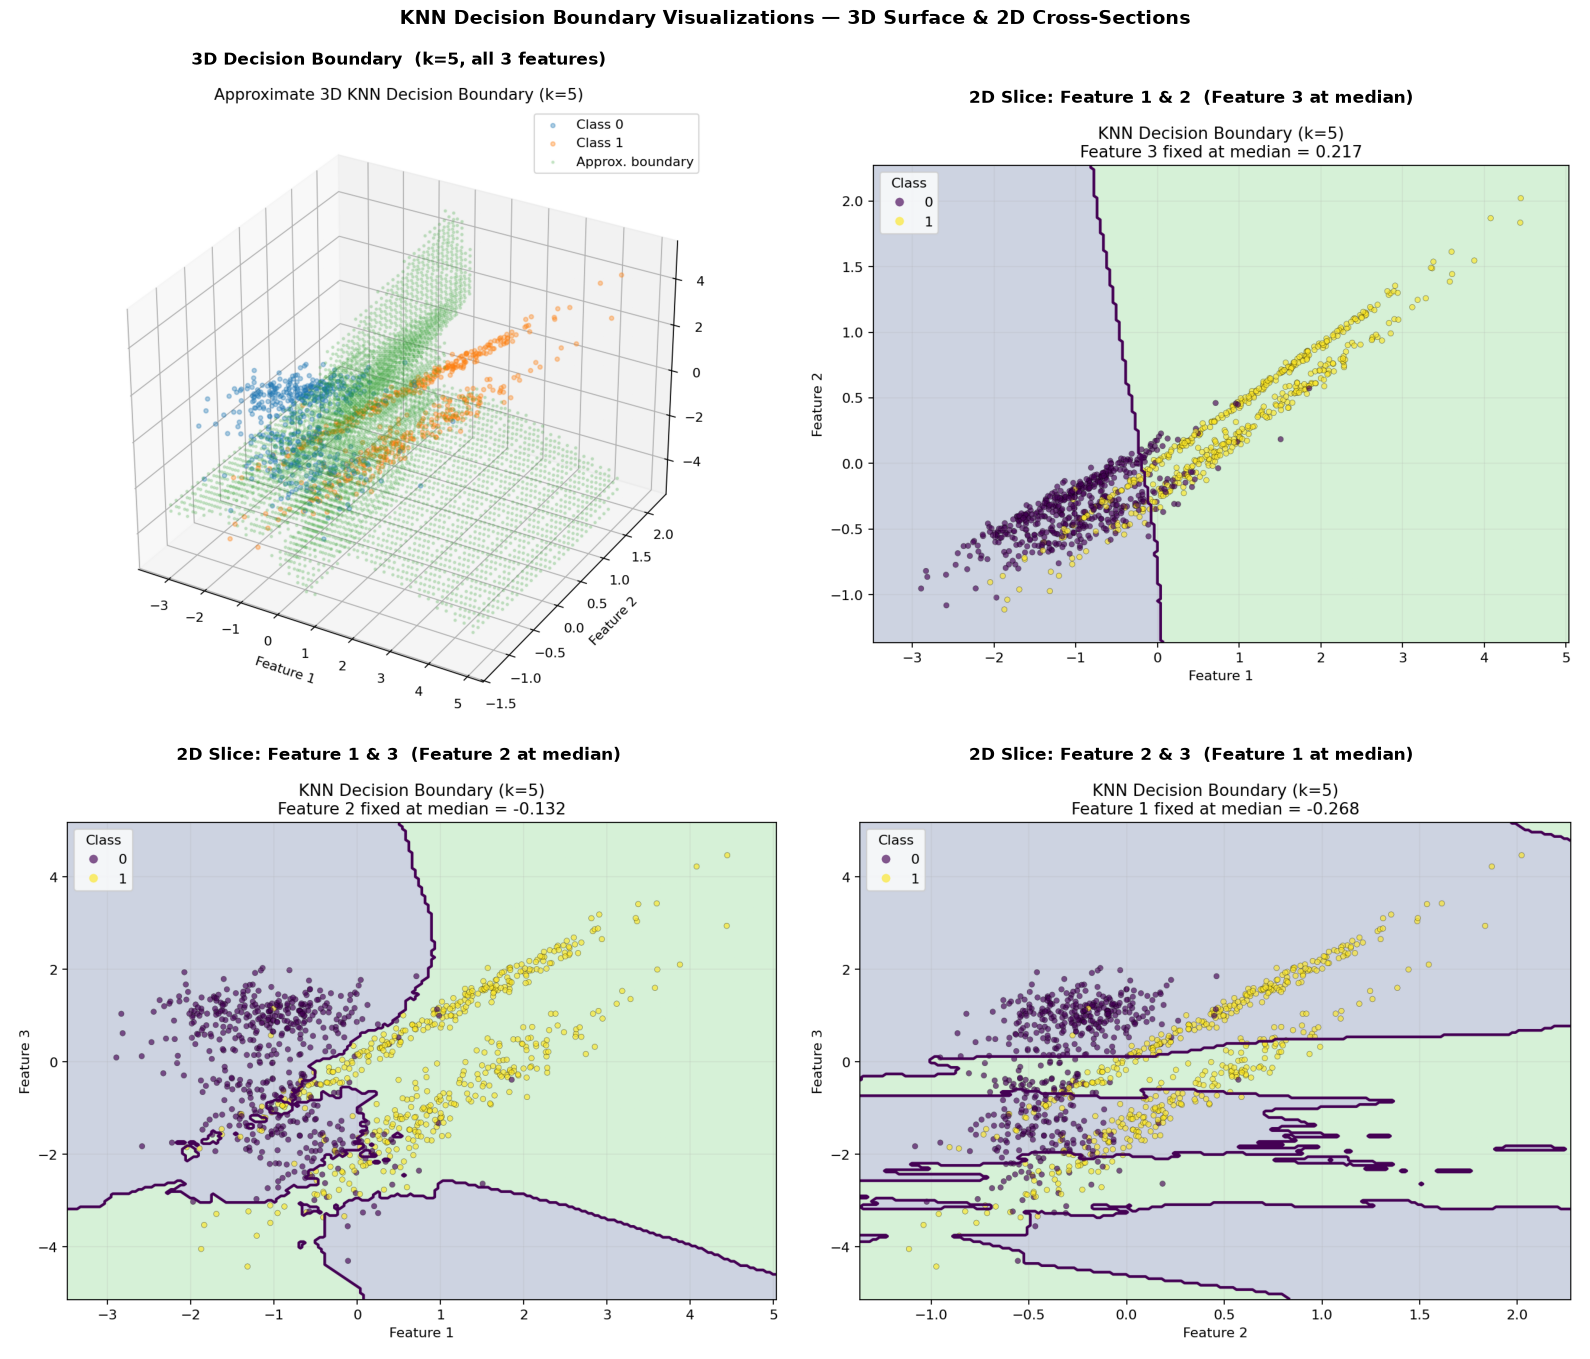

Decision Boundary Interpretation:
• The TRUE boundary exists in 3D, separating all 3 features
• Each 2D slice shows a cross-section through a fixed value
• Simple boundary (F1-F2) → complex boundary (F2-F3)
  indicates class separation depends on all 3 features


In [47]:
# --- Plot 3: KNN Decision Boundary — 3D + 2D Slices ---
from matplotlib.image import imread

# Load all 4 pre-computed decision boundary images
img_3d = imread('images/KNNClassifier/decision_boundary_3d_k5.png')
img_f12 = imread('images/KNNClassifier/decision_boundary_features_1_2.png')
img_f13 = imread('images/KNNClassifier/decision_boundary_features_1_3.png')
img_f23 = imread('images/KNNClassifier/decision_boundary_features_2_3.png')

# Create a 2x2 grid to show all 4 visualizations
fig, axes = plt.subplots(2, 2, figsize=(16, 14))

# Top-left: 3D decision boundary
axes[0, 0].imshow(img_3d)
axes[0, 0].axis('off')
axes[0, 0].set_title('3D Decision Boundary  (k=5, all 3 features)', 
                     fontsize=12, fontweight='bold', pad=10)

# Top-right: Feature 1 & 2 slice
axes[0, 1].imshow(img_f12)
axes[0, 1].axis('off')
axes[0, 1].set_title('2D Slice: Feature 1 & 2  (Feature 3 at median)',
                     fontsize=12, fontweight='bold', pad=10)

# Bottom-left: Feature 1 & 3 slice
axes[1, 0].imshow(img_f13)
axes[1, 0].axis('off')
axes[1, 0].set_title('2D Slice: Feature 1 & 3  (Feature 2 at median)',
                     fontsize=12, fontweight='bold', pad=10)

# Bottom-right: Feature 2 & 3 slice
axes[1, 1].imshow(img_f23)
axes[1, 1].axis('off')
axes[1, 1].set_title('2D Slice: Feature 2 & 3  (Feature 1 at median)',
                     fontsize=12, fontweight='bold', pad=10)

plt.suptitle('KNN Decision Boundary Visualizations — 3D Surface & 2D Cross-Sections',
             fontsize=14, fontweight='bold', y=0.995)
plt.tight_layout()
plt.show()

print("Decision Boundary Interpretation:")
print("=" * 60)
print("• The TRUE boundary exists in 3D, separating all 3 features")
print("• Each 2D slice shows a cross-section through a fixed value")
print("• Simple boundary (F1-F2) → complex boundary (F2-F3)")
print("  indicates class separation depends on all 3 features")
print("=" * 60)

### Step 6: Make Predictions on the Test Set

Apply the trained classifier to all 330 test points. For each test point $\mathbf{x}_i \in X_{\text{test}}$, KNN:

1. Computes distances to all 670 training points
2. Selects the $k = 5$ nearest neighbors
3. Returns the majority class label

$$\hat{y}_i = \text{mode}\bigl\{y_j : j \in \mathcal{N}_5(\mathbf{x}_i)\bigr\}, \qquad i = 1, \ldots, 330$$

The result `y_pred` is an array of 330 predicted labels $\in \{0, 1\}$.

---

#### The 3 Core Algorithm Steps (Scikit-Learn Does All Internally)

The three steps above map directly to the ***from-scratch KNN algorithm***:

| Step | From-Scratch Implementation | Scikit-Learn Equivalent |
|---|---|---|
| **1. Distance computation** | Manually compute Euclidean distance to all training points | `classifier.predict(X_test)` computes all distances internally |
| **2. Neighbor selection** | Sort distances and pick top-$k$ closest points | Automatically selects $k=5$ nearest neighbors |
| **3. Majority voting** | Take the most frequent class among $k$ neighbors | Returns the majority class label |

> [!IMPORTANT]
> When you call `classifier.predict(X_test)`, ***scikit-learn performs all three steps automatically under the hood using optimized C/Cython code***. You don't write any loops or manual distance calculations — it's all handled transparently for all 330 test points at once.

**What actually happens when you run `classifier.predict(X_test)`:**

```
For each of 330 test points:
  1. Compute Euclidean distance to all 670 training points  ← Distance computation
  2. Sort distances and select the 5 nearest              ← Neighbor selection
  3. Count votes: majority class among those 5            ← Majority voting
  4. Store the predicted label in y_pred
```

This entire process happens **inside scikit-learn** — you just call one method and get the results back.

In [48]:
y_pred=classifier.predict(X_test)
y_pred

array([1, 0, 1, 1, 1, 0, 0, 0, 1, 1, 0, 0, 1, 0, 1, 0, 0, 0, 1, 0, 1, 1,
       0, 0, 1, 1, 0, 1, 0, 0, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 1, 0, 1,
       0, 1, 1, 0, 0, 0, 1, 1, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 0,
       1, 0, 0, 1, 1, 1, 1, 1, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 1, 0,
       0, 1, 1, 0, 0, 0, 1, 1, 0, 1, 0, 1, 0, 1, 1, 1, 0, 1, 1, 0, 1, 0,
       0, 1, 0, 1, 0, 1, 0, 1, 0, 0, 1, 1, 1, 0, 1, 1, 1, 0, 0, 0, 0, 0,
       0, 0, 1, 0, 1, 0, 1, 1, 1, 0, 1, 0, 1, 0, 0, 0, 1, 1, 1, 0, 0, 0,
       0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 1,
       0, 1, 0, 1, 1, 1, 1, 0, 0, 0, 0, 1, 0, 1, 1, 1, 1, 1, 1, 0, 0, 0,
       0, 0, 1, 1, 0, 1, 1, 0, 1, 1, 0, 0, 0, 0, 1, 1, 0, 0, 1, 0, 0, 0,
       0, 0, 1, 0, 1, 1, 1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 1, 1, 0, 1, 0,
       1, 1, 0, 1, 0, 1, 1, 0, 1, 1, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 1,
       1, 0, 1, 0, 0, 0, 1, 0, 0, 1, 1, 1, 0, 1, 0, 1, 1, 0, 1, 1, 0, 1,
       0, 0, 1, 1, 1, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0,

### Step 7: Evaluate the Model

Measure classification performance using the **confusion matrix**, **accuracy**, and a full **classification report** (precision, recall, F1-score per class).

**Confusion Matrix** (rows = predicted, columns = actual):

$$\begin{pmatrix} TN & FP \\ FN & TP \end{pmatrix}$$

**Accuracy** — fraction of all predictions that are correct:

$$\text{Accuracy} = \frac{TP + TN}{TP + TN + FP + FN}$$

**Precision** — of all points predicted positive, how many truly are:

$$\text{Precision} = \frac{TP}{TP + FP}$$

**Recall** — of all actual positives, how many were correctly identified:

$$\text{Recall} = \frac{TP}{TP + FN}$$

**F1-Score** — harmonic mean of precision and recall (balances both):

$$F_1 = 2 \times \frac{\text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}}$$

| Metric | Range | Best Value |
|---|---|---|
| Accuracy | [0, 1] | 1.0 |
| Precision | [0, 1] | 1.0 |
| Recall | [0, 1] | 1.0 |
| F1-Score | [0, 1] | 1.0 |

In [49]:
from sklearn.metrics import confusion_matrix,accuracy_score,classification_report

In [50]:
print(confusion_matrix(y_pred,y_test))
print(accuracy_score(y_pred,y_test))
print(classification_report(y_pred,y_test))

[[158  20]
 [ 11 141]]
0.906060606060606
              precision    recall  f1-score   support

           0       0.93      0.89      0.91       178
           1       0.88      0.93      0.90       152

    accuracy                           0.91       330
   macro avg       0.91      0.91      0.91       330
weighted avg       0.91      0.91      0.91       330



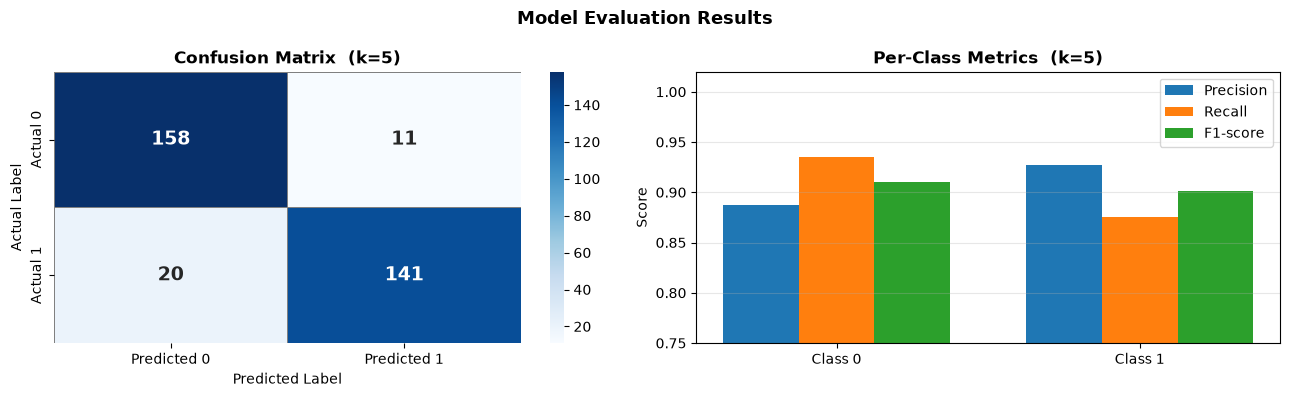

TN=158  FP=11  FN=20  TP=141
Accuracy = (141+158) / 330 = 0.9061


In [51]:
# --- Plot 4: Confusion Matrix Heatmap + Per-Class Metrics Bar Chart ---
cm = confusion_matrix(y_test, y_pred)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Left: heatmap
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Predicted 0', 'Predicted 1'],
            yticklabels=['Actual 0',    'Actual 1'],
            linewidths=0.5, linecolor='gray',
            annot_kws={'size': 14, 'weight': 'bold'})
axes[0].set_title('Confusion Matrix  (k=5)', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Actual Label')
axes[0].set_xlabel('Predicted Label')

# Right: per-class precision / recall / f1 bar chart
report = classification_report(y_test, y_pred, output_dict=True)
classes  = ['0', '1']
metrics  = ['precision', 'recall', 'f1-score']
x, width = np.arange(len(classes)), 0.25

for i, metric in enumerate(metrics):
    vals = [report[c][metric] for c in classes]
    axes[1].bar(x + i * width, vals, width, label=metric.capitalize())

axes[1].set_title('Per-Class Metrics  (k=5)', fontsize=12, fontweight='bold')
axes[1].set_xticks(x + width)
axes[1].set_xticklabels(['Class 0', 'Class 1'])
axes[1].set_ylim(0.75, 1.02)
axes[1].set_ylabel('Score')
axes[1].legend()
axes[1].grid(True, alpha=0.3, axis='y')

plt.suptitle('Model Evaluation Results', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f'TN={tn}  FP={fp}  FN={fn}  TP={tp}')
print(f'Accuracy = ({tp}+{tn}) / {len(y_test)} = {(tp+tn)/len(y_test):.4f}')

### Task: Find the Best K using Cross-Validation (CV)

Use 5-fold cross-validation to compare KNN accuracy for $k = 1$ to $k = 20$.

**Goal:** Find the value of $k$ that maximizes validation accuracy without overfitting.

| k is too small | k is optimal | k is too large |
|---|---|---|
| Overfits — high variance | Best generalization | Underfits — high bias |
| Train accuracy ≈ 100% | Train and CV accuracy are close | Both train and CV accuracy are lower |

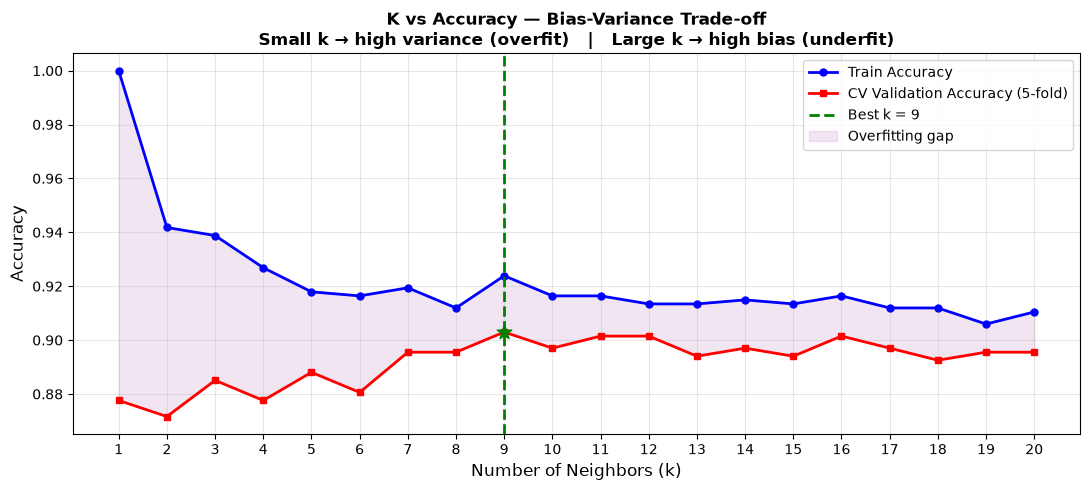

Best k = 9  |  CV Accuracy = 0.9030

  k   Train Acc      CV Acc
----------------------------
  1      1.0000      0.8776
  2      0.9418      0.8716
  3      0.9388      0.8851
  4      0.9269      0.8776
  5      0.9179      0.8881
  6      0.9164      0.8806
  7      0.9194      0.8955
  8      0.9119      0.8955
  9      0.9239      0.9030 ◄ best
 10      0.9164      0.8970
 11      0.9164      0.9015
 12      0.9134      0.9015
 13      0.9134      0.8940
 14      0.9149      0.8970
 15      0.9134      0.8940
 16      0.9164      0.9015
 17      0.9119      0.8970
 18      0.9119      0.8925
 19      0.9060      0.8955
 20      0.9104      0.8955


In [52]:
# --- Plot 5: K vs Accuracy — Bias-Variance Trade-off ---
from sklearn.model_selection import cross_val_score

k_range   = range(1, 21)
train_acc = []
cv_acc    = []

for k in k_range:
    knn_k = KNeighborsClassifier(n_neighbors=k, algorithm='auto')
    knn_k.fit(X_train, y_train)
    train_acc.append(knn_k.score(X_train, y_train))
    cv_acc.append(cross_val_score(knn_k, X_train, y_train, cv=5).mean())

best_k = list(k_range)[np.argmax(cv_acc)]

plt.figure(figsize=(11, 5))
plt.plot(list(k_range), train_acc, 'b-o', label='Train Accuracy',
         linewidth=2, markersize=5)
plt.plot(list(k_range), cv_acc,   'r-s', label='CV Validation Accuracy (5-fold)',
         linewidth=2, markersize=5)
plt.axvline(x=best_k, color='green', linestyle='--', linewidth=2,
            label=f'Best k = {best_k}')
plt.scatter([best_k], [max(cv_acc)], color='green', zorder=5, s=120, marker='*')
plt.fill_between(list(k_range), train_acc, cv_acc,
                 alpha=0.1, color='purple', label='Overfitting gap')

plt.xlabel('Number of Neighbors (k)', fontsize=12)
plt.ylabel('Accuracy', fontsize=12)
plt.title('K vs Accuracy — Bias-Variance Trade-off\n'
          'Small k → high variance (overfit)   |   Large k → high bias (underfit)',
          fontsize=12, fontweight='bold')
plt.legend(fontsize=10)
plt.grid(True, alpha=0.3)
plt.xticks(list(k_range))
plt.tight_layout()
plt.show()

print(f'Best k = {best_k}  |  CV Accuracy = {max(cv_acc):.4f}')
print()
print(f'{"k":>3}  {"Train Acc":>10}  {"CV Acc":>10}')
print('-' * 28)
for k, tr, cv in zip(k_range, train_acc, cv_acc):
    marker = ' ◄ best' if k == best_k else ''
    print(f'{k:>3}  {tr:>10.4f}  {cv:>10.4f}{marker}')

---

<p align="center">
  ⬅️ <strong>Previous:</strong> <a href="./04.1%20KNN%20Classifier%20From%20Scratch.ipynb">04.1 KNN Classifier From Scratch</a> &nbsp;&nbsp;|&nbsp;&nbsp; <strong>Next:</strong> <a href="./04.3%20KNN%20Regressor%20From%20Scratch.ipynb">04.3 KNN Regressor From Scratch</a> ➡️
</p>